# Device selection

In [1]:
channel = "ibm_quantum"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
device = "ibm_marrakesh"
# device = "ibm_aachen"
# device = "ibm_kingston"

# Auxiliary lattice plot

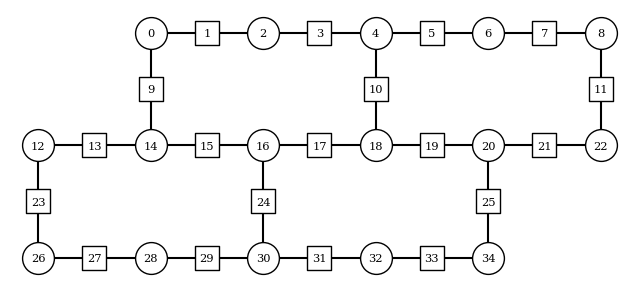

In [2]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 2
plaquette_height = 2

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
lattice.plot_lattice(number_qubits=True)

# Simulation settings

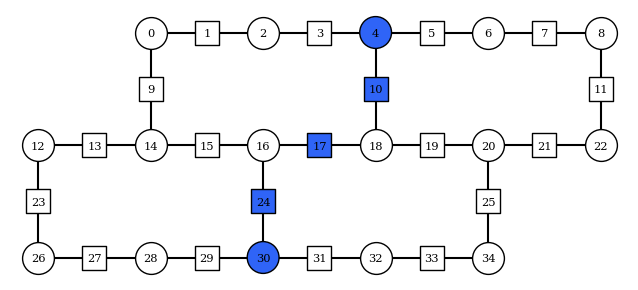

In [3]:
from z2hex.gdd import zero_mean
from utils.hexec import create_estimator_options
from utils.execrecord import ExecutionRecord
from utils.hexec import ExecDB
from functools import partial

lattice_dims = (plaquette_width, plaquette_height)
J = 5
h = 2
lamb = 1

x_basis = False

fractional_gates = False

# string = [27, 26, 34, 43, 52, 60, 59]
string = [4, 10, 17, 24, 30]
# string = [1, 2, 9, 15, 19, 16, 17, 21, 22, 24, 26, 27, 29]

final_time = 4.5
dt = 0.15
steps = 30
desired_error = 1e-2

confidence = 0.9

odr = True
postselect_odr = True
flip_threshold = 1
all_or_first_layout_qubit = None
forbidden_qubits = []
max_layouts = 5
recovery = True
# g_func = None
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = zero_mean

pt_num_randomizations = 60
pt_shots_per_randomization = 5000

shots = pt_num_randomizations * pt_shots_per_randomization
max_shots = 100000
# shots = 75000
# max_shots = 75000

final_twirl_randomizations = pt_num_randomizations
if shots > max_shots:
    final_twirl_randomizations = int(final_twirl_randomizations * max_shots / shots)
if all_or_first_layout_qubit == True:
    final_twirl_randomizations = int(final_twirl_randomizations/max_layouts)
# if final_twirl_randomizations < 1:
#     final_twirl_randomizations = 1

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": False,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": final_twirl_randomizations,
        "shots_per_randomization": pt_shots_per_randomization
    }
}
# execution_database = "z2_hex_jobs_dec.json" # Last db with good jobs / Not in the new order
execution_database = "z2_hex_jobs.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

curated_data_folder_path = "Curated data/"

lattice.plot_highlighted_qubits(string, colors=["#2f64f7"]*len(string), number_qubits=True, filepath="z2hex_quench_initial_state.png")

# Load data

In [4]:
from utils.postselection_multithreaded import load_postselected_jobs_obs
import pickle
import os

curated_data_filepath = os.path.join(curated_data_folder_path, f"z2hexquench_curated_data_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else g_func}_shots_{shots}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}_dd_{sampler_options["dynamical_decoupling"]["enable"]}_pt_{sampler_options["twirling"]["enable_gates"]}_ft_{flip_threshold}_pODR_{postselect_odr}_confidence_{confidence}.pkl")

with open(curated_data_filepath, "rb") as f:
    hardware_observables, hardware_observables_confidence, samples_dicts, postselected_samples_dicts, layouts = pickle.load(f)

# With number operator

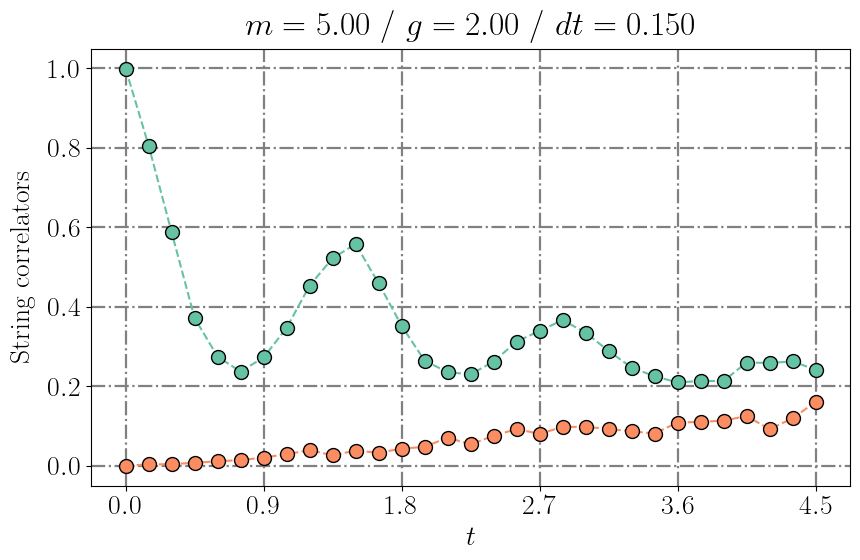

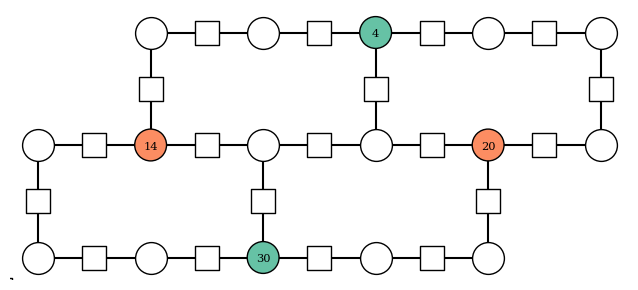

In [5]:
from utils.plotting import plot_individual_qubits_observable_evolution
from utils.observables import load_projection_operators
import matplotlib.pyplot as plt
import numpy as np

J = 5
h = 2
lamb = 1

string = [4, 10, 17, 24, 30]

final_time = 4.5
dt = 0.15

samples_dicts_to_plot = postselected_samples_dicts[0][0]
samples_dicts_to_cal = postselected_samples_dicts[1][0]
# string_qubits = [
#     [2, 16, 22, 26],
#     [2, 16, 26, 32]
# ]
string_qubits = [
    [4, 30],
    [14, 20]
]

labels = [
    "-".join([str(i) for i in st]) for st in string_qubits
]

cmap = plt.get_cmap("Set2")
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"String correlators"
y_lim = None # "data" for data limits, None for auto, [,] for custom
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$"
legend = False

occupation_operators_vals, occupation_operators_confidence = load_projection_operators(samples_dicts_to_plot, string_qubits, cal_samples_dicts=samples_dicts_to_cal, confidence=0.9, shots=shots)

qubits = [x for xs in string_qubits for x in xs]
to_plot_string_qubits = list(set(string) - set(qubits))
colors = []
for i, s in enumerate(string_qubits):
    colors += [cmap(i%8)]*len(s)
colors += ["#2f64f7"]*len(to_plot_string_qubits)

observables_to_plot = occupation_operators_vals[0]
observables_stdm = None #occupation_operators_confidence[0]

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=None, function_over=None, ylabel=y_label, cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--")
lattice.plot_highlighted_qubits(qubits, colors=colors)

# As sum of Pauli correlators

In [8]:
from utils.postselection_multithreaded import measure_diagonal_observables
from z2chain.operators import pauli_z_tensor
from multiprocessing import Pool, cpu_count
from itertools import product, combinations
import utils.odr as odr

def load_single_occupation_correlators_paulis(samples_dict, occupied_qubits, confidence=None, shots=None):
    # Generate the pauli observable list involved in the correlator
    nqubits = len(list(samples_dict.keys())[0])
    pauli_zs = []
    signs = []
    for i in range(1, len(occupied_qubits)+1):
        these_pauli_zs = []
        for comb in combinations(occupied_qubits, i):
            these_pauli_zs.append(pauli_z_tensor(nqubits, comb))
        signs += [(-1)**i]*len(these_pauli_zs)
        pauli_zs += these_pauli_zs
    if confidence is not None:
        evals, evals_confidence = measure_diagonal_observables(samples_dict, pauli_zs, confidence=confidence)
        return (evals, evals_confidence, signs)
    else:
        evals = measure_diagonal_observables(samples_dict, pauli_zs, confidence=confidence)
        return (evals, signs)
    
def _paulis_results_to_occ_corrs(results, occupied_qubits):
    confidence_present = (len(results[0]) == 3)
    occ_qb_paulisz_evals = np.array([r[0] for r in results])
    if confidence_present:
        occ_qb_paulisz_confidence = np.array([r[1] for r in results])
    occ_qb_paulisz_signs = np.array([r[-1] for r in results])

    nsamples_dicts = len(occ_qb_paulisz_evals)//len(occupied_qubits)
    occupation_correlators_evals = np.zeros((nsamples_dicts, len(occupied_qubits)))
    if confidence_present:
        occupation_correlators_confidence = np.zeros((nsamples_dicts, len(occupied_qubits), 2))
    for i, occ_qb in enumerate(occupied_qubits):
        this_occ_qb_paulisz_evals = occ_qb_paulisz_evals[i*nsamples_dicts:(i+1)*nsamples_dicts]
        this_occ_qb_paulisz_signs = occ_qb_paulisz_signs[i*nsamples_dicts:(i+1)*nsamples_dicts]
        occupation_correlators_evals[:, i] = (1 + np.sum(this_occ_qb_paulisz_evals * this_occ_qb_paulisz_signs, axis=1))/2**len(occ_qb)
        if confidence_present:
            this_occ_qb_paulisz_confidence = occ_qb_paulisz_confidence[i*nsamples_dicts:(i+1)*nsamples_dicts]
            confidence_deltas = np.abs(this_occ_qb_paulisz_confidence - this_occ_qb_paulisz_evals.reshape((*this_occ_qb_paulisz_confidence.shape[:2], 1)))
            confidence_deltas = np.abs(np.sum(confidence_deltas * this_occ_qb_paulisz_signs.reshape((*this_occ_qb_paulisz_confidence.shape[:2], 1)), axis=1)/2**len(occ_qb))
            occupation_correlators_confidence[:, i, 0] = occupation_correlators_evals[:, i] - confidence_deltas[:, 0]
            occupation_correlators_confidence[:, i, 1] = occupation_correlators_evals[:, i] + confidence_deltas[:, 1]
    
    to_return = [occupation_correlators_evals]
    if confidence_present:
        to_return.append(occupation_correlators_confidence)
    return to_return

def load_occupation_correlators_bypaulis(samples_dicts, occupied_qubits, cal_samples_dicts=None, confidence=None, shots=None):
    if isinstance(samples_dicts, dict):
        samples_dicts = [samples_dicts]
    elif not isinstance(samples_dicts, (list, tuple, np.ndarray)):
        raise ValueError("samples_dicts must be a list, tuple, or numpy array")
    samples_dicts = np.array(samples_dicts, dtype=object)
    if isinstance(occupied_qubits[0], int):
        occupied_qubits = [occupied_qubits]
    elif not isinstance(occupied_qubits, (list, tuple, np.ndarray)):
        raise ValueError("occupied_qubits must be list of list of indices")
    if len(samples_dicts.shape) != 1:
        raise ValueError("samples_dicts must be a 1D array of dictionaries")
    if cal_samples_dicts is not None:
        cal_samples_dicts = np.array(cal_samples_dicts, dtype=object)
        if cal_samples_dicts.shape != samples_dicts.shape:
            raise ValueError("cal_samples_dicts must have the same shape as samples_dicts")
        
    results = []
    cal_results = []
    for i, occ_qbs in enumerate(occupied_qubits):
        for j, samples_dict in enumerate(samples_dicts):
            results.append(load_single_occupation_correlators_paulis(samples_dict, occ_qbs, confidence=confidence, shots=shots))
            if cal_samples_dicts is not None:
                cal_results.append(load_single_occupation_correlators_paulis(cal_samples_dicts[j], occ_qbs, confidence=confidence, shots=shots))

    # process_args = [(samples_dict, occ_qbs, confidence, shots) for occ_qbs, samples_dict in product(occupied_qubits, samples_dicts)]
    # process_args_cal = [(samples_dict, occ_qbs, confidence, shots) for occ_qbs, samples_dict in product(occupied_qubits, cal_samples_dicts)]
    # with Pool(processes=cpu_count()) as pool:
    #     results = pool.starmap(load_single_occupation_correlators_paulis, process_args)
    #     if cal_samples_dicts is not None:
    #         cal_results = pool.starmap(load_single_occupation_correlators_paulis, process_args_cal)

    if confidence is not None:
        occupation_correlators_evals, occupation_correlators_confidence = _paulis_results_to_occ_corrs(results, occupied_qubits)
        if cal_samples_dicts is not None:
            cal_occupation_correlators_evals, cal_occupation_correlators_confidence = _paulis_results_to_occ_corrs(cal_results, occupied_qubits)
            corrected_occupation_correlators_evals = np.zeros_like(occupation_correlators_evals)
            corrected_occupation_correlators_confidence = np.zeros_like(occupation_correlators_confidence)
            for i in range(cal_occupation_correlators_evals.shape[1]):
                p_arr = odr.compute_depolarizing_probability(cal_occupation_correlators_evals[:, i], 1, 0, 0)
                corrected_occupation_correlators_evals[:, i], corrected_occupation_correlators_confidence[:, i, :] = odr.renormalize_observable(occupation_correlators_evals[:, i], p_arr, 0, 0, observable_range=[1, -1], observable_confidence=occupation_operators_confidence[:, i, :], expected_observable_arr=1)
            return [corrected_occupation_correlators_evals, occupation_correlators_evals, cal_occupation_correlators_evals], [corrected_occupation_correlators_confidence, occupation_correlators_confidence, cal_occupation_correlators_confidence]
        return [occupation_correlators_evals, cal_occupation_correlators_evals], [occupation_correlators_confidence, cal_occupation_correlators_confidence]
    else:
        occupation_correlators_evals = _paulis_results_to_occ_corrs(results, occupied_qubits)
        if cal_samples_dicts is not None:
            cal_occupation_correlators_evals = _paulis_results_to_occ_corrs(cal_results, occupied_qubits)
            corrected_occupation_correlators_evals = np.zeros_like(occupation_correlators_evals)
            for i in range(cal_occupation_correlators_evals.shape[1]):
                p_arr = odr.compute_depolarizing_probability(cal_occupation_correlators_evals, 1, 0, 0)
                corrected_occupation_correlators_evals[:, i] = odr.renormalize_observable(occupation_correlators_evals, p_arr, 0, 0, observable_range=[1, -1], expected_observable_arr=1)
                return corrected_occupation_correlators_evals, occupation_correlators_evals, cal_occupation_correlators_evals
        return occupation_correlators_evals

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt
import numpy as np

J = 5
h = 2
lamb = 1

string = [4, 10, 17, 24, 30]

final_time = 4.5
dt = 0.15

samples_dicts_to_plot = postselected_samples_dicts[0][0]
samples_dicts_to_cal = postselected_samples_dicts[1][0]
# string_qubits = [
#     [2, 16, 22, 26],
#     [2, 16, 26, 32]
# ]
occupied_qubits = [
    [4, 30],
    [14, 20]
]

labels = [
    "-".join([str(i) for i in st]) for st in string_qubits
]

cmap = plt.get_cmap("Set2")
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"String correlators"
y_lim = None # "data" for data limits, None for auto, [,] for custom
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$"
legend = False

occupation_operators_vals, occupation_operators_confidence = load_occupation_correlators_bypaulis(postselected_samples_dicts[0][0], occupied_qubits, samples_dicts_to_cal, 0.9, None)

qubits = [x for xs in string_qubits for x in xs]
to_plot_string_qubits = list(set(string) - set(qubits))
colors = []
for i, s in enumerate(string_qubits):
    colors += [cmap(i%8)]*len(s)
colors += ["#2f64f7"]*len(to_plot_string_qubits)

observables_to_plot = occupation_operators_vals[1]
observables_stdm = occupation_operators_confidence[1]

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=y_label, cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--")
lattice.plot_highlighted_qubits(qubits, colors=colors)